# The first seconds of a memecoin launch: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_memecoin_launch_outcomes.md`](../../research/idea_memecoin_launch_outcomes.md):

1. **Data.** 1.18 million pump.fun launches with creator, name, an early snapshot and outcomes.
2. **Bundling and names.** What the two signals of the idea look like in the data.
3. **Preprocessing and split.** The moment of prediction, what is known then, the targets, a split by time, leakage checks.
4. **Baseline.** Task, metrics, protocol, a fixed baseline, and candidate models on the development day.
5. **Method fit.** Whether survival models and name matching suit the data.

The literature review is in [`research/literature/literature_review_memecoin_launches.md`](../../research/literature/literature_review_memecoin_launches.md)
and the conclusions are in [`research/memecoin_launch_writeup.md`](../../research/memecoin_launch_writeup.md).

Reusable code lives in `src/scripts/pumpfun.py`, with tests in `tests/test_pumpfun.py`.
The notebook runs in a few minutes once the data is in place.

Token names are text written by token creators. They are handled as data throughout and only a few are printed, truncated.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.duration.hazard_regression import PHReg

sys.path.append("../scripts")
import pumpfun as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)

DEV_START, TEST_START = "2026-10-01", "2026-10-02"   # train: 27 to 30 September; dev: 1 October; test: 2 and 3 October
HORIZON = 60.0                                        # seconds after the prediction moment for "the creator sells"
SEED = 0

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})
BUNDLE_BINS, BUNDLE_LABELS = [-1, 0, 2, 5, 99], ["0", "1 to 2", "3 to 5", "6 or more"]
BUNDLE_COLOURS = dict(zip(BUNDLE_LABELS, [BLUE, AQUA, YELLOW, ORANGE]))

## 1. Data

**How pump.fun works.** Anyone can create a token for a few dollars. It trades at once on a *bonding
curve*: a contract that sells tokens at a price that rises with the SOL paid in. When about 85 SOL
have been paid in, the token *graduates* to an ordinary exchange pool. The creator can buy in the
creating transaction itself, and other wallets can buy in the same instant: a *bundle*.

**Source.** The public dataset
[`loopholetape/pumpfun-launches`](https://huggingface.co/datasets/loopholetape/pumpfun-launches) on
Hugging Face (licence CC BY 4.0), release of 10 October 2026, downloaded at a pinned revision into
`data/pumpfun_launches/` by `pf.download()` (157 MB). One row per launch. The author's
`KNOWN_ISSUES.md` (17 documented issues) is the basis for most decisions below.

**Two recording regimes.** Before 27 September 2026 the recorder missed about half of the buys
(`launches_legacy`); from then on it is complete (`launches`). Bundle features and the rug label are
reliable in the complete part only.

In [2]:
everything = pf.load_launches("all")
everything["name_key"] = everything["name"].map(pf.normalize_name)

by_subset = everything.groupby(everything["decoder_complete"].map({0: "legacy (buys undercounted)", 1: "complete"})).agg(
    launches=("mint", "size"), first_day=("day", "min"), last_day=("day", "max"), days=("day", "nunique"),
    creators=("creator", "nunique"), distinct_names=("name", "nunique"))
display(by_subset)
print(f"{len(everything):,} launches, {everything['creator'].nunique():,} creators, columns: {everything.shape[1] - 3}")
print("duplicate mints:", int(everything["mint"].duplicated().sum()))

,launches,first_day,last_day,days,creators,distinct_names
decoder_complete,,,,,,
complete,321041,2026-09-27,2026-10-03,7,90835,119953
legacy (buys undercounted),859828,2026-08-31,2026-09-27,28,186860,308086


1,180,869 launches, 267,328 creators, columns: 43


duplicate mints: 0


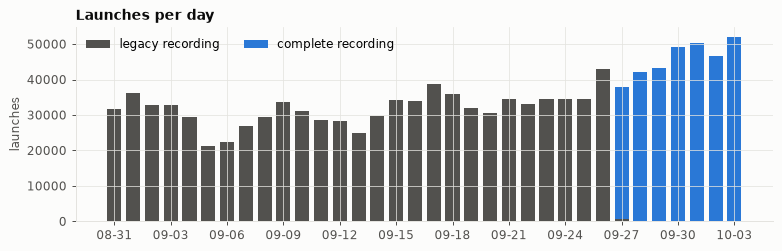

In [3]:
daily = everything.groupby(["day", "decoder_complete"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 2.8))
x = np.arange(len(daily))
ax.bar(x, daily.get(0, 0), color=MUTED, width=0.75, label="legacy recording")
ax.bar(x, daily.get(1, 0), bottom=daily.get(0, 0), color=BLUE, width=0.75, label="complete recording")
ax.set_xticks(x[::3]); ax.set_xticklabels([d[5:] for d in daily.index[::3]])
ax.set_title("Launches per day"); ax.set_ylabel("launches"); ax.legend(loc="upper left", ncol=2)
plt.show()

### 1.1 Checking the documentation against the files

The complete part, day by day: the kind of launch, how often the early snapshot exists, and how often the
outcome is unresolved.

In [4]:
complete = everything[everything["decoder_complete"] == 1]
per_day = complete.groupby("day").agg(
    launches=("mint", "size"),
    mayhem=("mayhem", "mean"),
    not_sol=("quote_asset", lambda s: (s != "sol").mean()),
    snapshot=("f10_rs", lambda s: s.notna().mean()),
    full_snapshot=("f10_bundle_wallets", lambda s: s.notna().mean()),
    unresolved=("rugged", lambda s: s.isna().mean()),
    graduated=("graduated", "mean"),
)
display(per_day)
window = (complete["time"] >= pd.Timestamp(pf.UNRESOLVED_WINDOW[0], tz="UTC")) & (complete["time"] < pd.Timestamp(pf.UNRESOLVED_WINDOW[1], tz="UTC"))
print(f"unresolved inside 30 September 00:00 to 03:00 UTC: {complete[window & (complete['quote_asset'] == 'sol')]['rugged'].isna().mean():.1%} of SOL launches there")

,launches,mayhem,not_sol,snapshot,full_snapshot,unresolved,graduated
day,,,,,,,
2026-09-27,37288,0.2842,0.0782,0.8897,0.9650,0.0827,0.0207
2026-09-28,42266,0.2545,0.0927,0.8917,0.9832,0.0988,0.0237
2026-09-29,43327,0.2668,0.1187,0.8579,0.9728,0.1293,0.0214
2026-09-30,49042,0.3045,0.1078,0.7555,0.8415,0.1602,0.0210
2026-10-01,50350,0.2795,0.1157,0.8223,0.9280,0.1186,0.0219
2026-10-02,46645,0.2685,0.1013,0.8653,0.9620,0.1054,0.0220
2026-10-03,52123,0.2675,0.0626,0.9031,0.9637,0.0677,0.0193


unresolved inside 30 September 00:00 to 03:00 UTC: 42.5% of SOL launches there


The files match the documentation: 321,041 completely recorded launches, a quarter to a third of them in
"mayhem" mode, 6 to 12% not quoted in SOL, a full snapshot on 84 to 98% of the SOL launches that have
one at all, and 42% of the SOL launches of the first three hours of 30 September unresolved.

**Two special kinds of launch are set aside.** "Mayhem" launches (over a quarter) are a mode in which
pump.fun's own agent may trade the token; according to the documentation they almost never graduate.
Launches not quoted in SOL (about a tenth) have no SOL amounts. Both are different products with their
own rules. The study population is: classic, quoted in SOL, completely recorded, and outside the three
hours of 30 September whose outcomes the recorder never resolved.

In [5]:
everything = pf.add_creator_history(everything)
everything = pf.add_name_history(everything)
# The creator's record of selling fast: earlier launches whose first sale came within about a minute, and was already visible.
fast_sale = everything["t0"] + everything["dev_first_sell_dt_s"].where(everything["dev_first_sell_dt_s"] <= pf.PREDICTION_AGE + HORIZON)
everything["cr_n_fast"] = pf.count_before(everything["creator"], everything["t0"], everything["creator"], fast_sale)
everything["cr_fast_rate"] = everything["cr_n_fast"] / everything["cr_n_prior"].where(everything["cr_n_prior"] > 0)

study = pf.study_population(everything)
study["outcome"] = pf.outcome(study)
funnel = pd.Series({
    "all launches, complete recording": len(complete),
    "classic (not mayhem)": int((complete["mayhem"] == 0).sum()),
    "classic and quoted in SOL": int(((complete["mayhem"] == 0) & (complete["quote_asset"] == "sol")).sum()),
    "outside the unresolved hours = study population": len(study),
}, name="launches")
display(funnel.to_frame())
print(f"creators in the study population: {study['creator'].nunique():,}")

,launches
"all launches, complete recording",321041
classic (not mayhem),232655
classic and quoted in SOL,204093
outside the unresolved hours = study population,199986


creators in the study population: 81,986


### 1.2 Outcomes

Each launch gets one outcome, in this order of precedence (`pf.outcome`):

| Outcome | Definition |
| --- | --- |
| creator buyout | the creator's own purchase at launch is 80 SOL or more: the whole curve is bought in the creating transaction |
| graduated | the curve completed otherwise |
| rug, dump | the dataset's rug rule fired on its "creator dump" branch: the creator sold at least half within 300 seconds |
| rug, drain | the rule fired on its "drain" branch: the curve held at least 5 SOL and later fell to a quarter of its peak |
| faded | resolved, and none of the above |
| unresolved | the recorder never closed the curve |

In [6]:
order = ["creator_buyout", "graduated", "rug_dump", "rug_drain", "faded", "unresolved"]
counts = study["outcome"].value_counts().reindex(order)
by_day = study.groupby("day")["outcome"].value_counts(normalize=True).unstack().reindex(columns=order)
display(pd.DataFrame({"launches": counts, "share": counts / len(study)}))
display(by_day)

graduated = study[study["graduated"] == 1]
buyout = graduated["dev_buy_sol"] >= pf.BUYOUT_SOL
print(f"graduations: {len(graduated):,}; of them creator buyouts: {buyout.mean():.1%}")
print(f"median seconds to migration: buyouts {graduated[buyout]['migrate_dt_s'].median():.2f}, others {graduated[~buyout]['migrate_dt_s'].median():.0f}")
print(f"buyouts whose curve is already full at the snapshot: {(graduated[buyout]['f10_rs'] >= 80).mean():.1%} of those with a snapshot")
print(f"other graduations that complete within 3 s of launch: {(graduated[~buyout]['migrate_dt_s'] <= 3).mean():.1%}")

,launches,share
outcome,,
creator_buyout,2720,0.0136
graduated,3352,0.0168
rug_dump,61228,0.3062
rug_drain,64088,0.3205
faded,66985,0.3349
unresolved,1613,0.0081


outcome,creator_buyout,graduated,rug_dump,rug_drain,faded,unresolved
day,,,,,,
2026-09-27,0.0123,0.0172,0.3000,0.3613,0.3025,0.0068
2026-09-28,0.0153,0.0171,0.2939,0.3351,0.3295,0.0092
2026-09-29,0.0144,0.0159,0.3237,0.3096,0.3196,0.0168
2026-09-30,0.0151,0.0170,0.3314,0.3252,0.3060,0.0053
2026-10-01,0.0139,0.0177,0.3116,0.3488,0.3032,0.0048
2026-10-02,0.0132,0.0176,0.3159,0.3170,0.3298,0.0065
2026-10-03,0.0116,0.0151,0.2758,0.2640,0.4260,0.0075


graduations: 6,072; of them creator buyouts: 44.8%
median seconds to migration: buyouts 0.00, others 175
buyouts whose curve is already full at the snapshot: 94.9% of those with a snapshot
other graduations that complete within 3 s of launch: 25.7%


Three things to note.

- **45% of all graduations are the creator buying the whole curve in the launch transaction.** They
  "graduate" at 0.00 seconds. That is not a token that found buyers; it is a different way of
  launching, and it is known at launch from the creator's purchase alone. The first look counted these
  as successes and as "graduated within ten seconds".
- **Of the other graduations, 26% still complete within three seconds,** when several wallets fill the
  curve together. A graduation that happens after the first seconds is about 1.1% of launches.
- **3 October looks different:** 43% faded against 30 to 33% on the other days. This is the newest day
  of the release. Whether the market changed or outcomes were still settling cannot be told from the
  files.

**Timing.** Seconds from launch to each event, over the launches where it happened.

,10%,25%,50%,75%,90%,n
"rug (dataset rule), dump branch",0.7900,5.3110,32.5150,95.7147,182.2876,61228
"rug (dataset rule), drain branch",2.8587,9.0065,27.0040,104.7785,358.3956,64088
creator's first sale,1.1620,3.0820,20.8940,133.4230,551.1782,141317
"graduation, not a buyout",0.0370,1.4240,175.0620,634.4460,"2,772.2040",3351


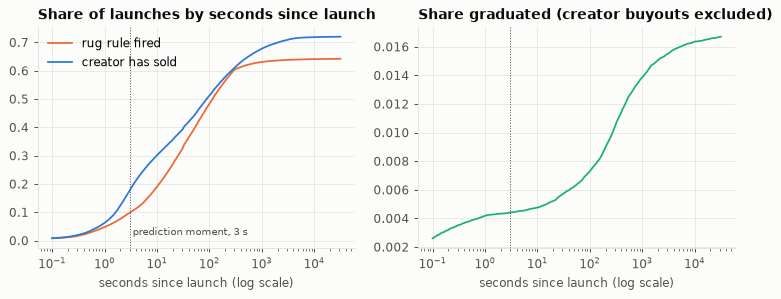

In [7]:
events = {
    "rug (dataset rule), dump branch": study.loc[study["outcome"] == "rug_dump", "rug_dt_s"],
    "rug (dataset rule), drain branch": study.loc[study["outcome"] == "rug_drain", "rug_dt_s"],
    "creator's first sale": study["dev_first_sell_dt_s"].dropna(),
    "graduation, not a buyout": study.loc[study["outcome"] == "graduated", "migrate_dt_s"].dropna(),
}
display(pd.DataFrame({k: v.quantile([0.1, 0.25, 0.5, 0.75, 0.9]) for k, v in events.items()}).T.rename(columns=lambda q: f"{int(q*100)}%").assign(n=[len(v) for v in events.values()]))

grid = np.logspace(-1, 4.5, 200)
resolved = study[study["outcome"] != "unresolved"]
not_buyout = resolved[resolved["outcome"] != "creator_buyout"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(grid, pf.event_share_by(not_buyout["rug_dt_s"].where(not_buyout["rugged"] == 1), grid), color=ORANGE, label="rug rule fired")
axes[0].plot(grid, pf.event_share_by(not_buyout["dev_first_sell_dt_s"], grid), color=BLUE, label="creator has sold")
axes[0].set_title("Share of launches by seconds since launch"); axes[0].legend(loc="upper left")
axes[1].plot(grid, pf.event_share_by(not_buyout["migrate_dt_s"].where(not_buyout["graduated"] == 1), grid), color=AQUA)
axes[1].set_title("Share graduated (creator buyouts excluded)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("seconds since launch (log scale)"); ax.axvline(pf.PREDICTION_AGE, color=MUTED, lw=0.8, ls=":")
axes[0].text(pf.PREDICTION_AGE * 1.15, 0.02, "prediction moment, 3 s", color=MUTED, fontsize=8)
plt.show()

A quarter of creators' first sales come within 3 seconds of launch and half within 21 seconds. The rug
rule fires at a median of about 30 seconds on either branch.

### 1.3 What the rug label measures

The idea was to relate bundling to the time until a rug. Before doing that, look at how the label
relates to the size the curve ever reached (`peak_rs`, in SOL).

In [8]:
size = pd.cut(resolved["peak_rs"], [-1, 0, 1, 5, 20, 80, 90], labels=["0", "0 to 1", "1 to 5", "5 to 20", "20 to 80", "80 or more"])
by_size = resolved.groupby(size, observed=True).agg(
    launches=("mint", "size"), rugged=("rugged", "mean"),
    drain_branch=("rug_branch_inferred", lambda s: (s == "drain").mean()),
    graduated=("graduated", "mean"), median_end_sol=("terminal_rs", "median"))
by_size.index.name = "peak SOL in the curve"
display(by_size)

,launches,rugged,drain_branch,graduated,median_end_sol
peak SOL in the curve,,,,,
0,20961,0.0000,0.0000,0.0000,0.0000
0 to 1,63418,0.4688,0.0000,0.0000,0.0000
1 to 5,43946,0.7194,0.0027,0.0000,0.0000
5 to 20,47434,0.9999,0.9999,0.0000,0.0000
20 to 80,16326,1.0000,0.9999,0.0000,0.0192
80 or more,6288,0.1412,0.0385,0.9656,85.0051


**This is the most important table of the data section.** Every curve that ever held 5 SOL and did not
graduate is labelled rugged: 99.99% of 47,434 and 100% of 16,326. The reason is in the last column. An
unfinished curve ends at zero, so the rule's condition, "fell to a quarter of its peak", is true of all
of them. Below 5 SOL that branch cannot fire and the label is the creator-dump branch alone.

So the label is, to a good approximation, *"the curve reached 5 SOL and did not graduate, or the
creator sold half within five minutes"*. The dataset's author says plainly that it is an observation
rule and not verified fraud. The consequence for this project is sharper than that: **"rugged or not"
is mostly "large or small"**, and bundle wallets are exactly what makes a curve large at launch. A
relation between bundling and this label is partly built in. Section 2 measures how much, and section
3.2 chooses targets that do not have the problem.

### 1.4 Creators and names

In [9]:
per_creator = study["creator"].value_counts()
top1 = per_creator.head(max(len(per_creator) // 100, 1)).sum() / len(study)
print(f"creators: {len(per_creator):,}; launching once: {(per_creator == 1).mean():.1%}; "
      f"top 1% of creators make {top1:.1%} of launches; largest: {per_creator.iloc[0]:,}")

raw_copies = study["name"].map(study["name"].value_counts())
key_copies = study["name_key"].map(study["name_key"].value_counts())
names = pd.Series({
    "distinct names, as written": study["name"].nunique(),
    "distinct names, normalized": study["name_key"].nunique(),
    "launches whose normalized name was used before (34 days of history)": (study["nm_n_prior"] > 0).mean(),
    "... before by the same creator": (study["nm_n_own"] > 0).mean(),
    "... before by other creators only": ((study["nm_n_prior"] > 0) & (study["nm_n_own"] == 0)).mean(),
    "launches in a name used 20 times or more this week": (key_copies >= 20).mean(),
    "launches with a name used once this week": (key_copies == 1).mean(),
}, name="value")
display(names.to_frame())

big = study[key_copies >= 20].groupby("name_key").agg(n=("mint", "size"), creators=("creator", "nunique"),
                                                      top_creator=("creator", lambda s: s.value_counts().iloc[0] / len(s)))
print(f"names used 20+ times this week: {len(big):,}; one creator makes over half of the launches in {(big['top_creator'] > 0.5).mean():.1%} of them")
print("median distinct creators per such name:", big["creators"].median())

creators: 81,986; launching once: 79.3%; top 1% of creators make 33.1% of launches; largest: 5,973


,value
"distinct names, as written","95,937.0000"
"distinct names, normalized","79,980.0000"
launches whose normalized name was used before (34 days of history),0.7134
... before by the same creator,0.1803
... before by other creators only,0.5331
launches in a name used 20 times or more this week,0.2150
launches with a name used once this week,0.2755


names used 20+ times this week: 1,132; one creator makes over half of the launches in 9.7% of them
median distinct creators per such name: 22.0


The first look reported one creator making over half the launches in 27% of the repeated names. On the
study population it is 10%: the first look included mayhem launches and matched names as written.
Repeated names are mostly many creators, with a median of 22 per name.

## 2. Bundling and names

Everything in this section and after is about launches that are still undecided **three seconds after
launch**: no creator buyout, no graduation or rug yet, and a full snapshot (section 3.1 gives the
reasons). `task` is that population.

In [10]:
task = pf.add_targets(study[pf.eligible_at_snapshot(study)], horizon=HORIZON)
task["bundle"] = pd.cut(task["f10_bundle_wallets"], BUNDLE_BINS, labels=BUNDLE_LABELS)
holders = task[task["dev_holds"]]
print(f"undecided at 3 s: {len(task):,} launches; creator holds tokens then: {len(holders):,} ({len(holders)/len(task):.1%})")

def rate_ci(frame, column):
    point, lo, hi = pf.cluster_bootstrap(np.mean, frame["creator"], frame[column], n_boot=200, seed=SEED)
    return f"{point:.1%} ({lo:.1%} to {hi:.1%})"

rows = []
for label in BUNDLE_LABELS:
    part, hold = task[task["bundle"] == label], holders[holders["bundle"] == label]
    rows.append({"bundle wallets": label, "launches": len(part), "median SOL in curve at 3 s": part["f10_rs"].median(),
                 "rug rule fires": rate_ci(part, "y_rug"), "graduates": rate_ci(part, "y_grad"),
                 "creator sells within 60 s": rate_ci(hold, "y_dev_exit"),
                 "median s to creator's first sale": hold["dev_first_sell_dt_s"].median()})
display(pd.DataFrame(rows).set_index("bundle wallets"))

undecided at 3 s: 165,381 launches; creator holds tokens then: 120,362 (72.8%)


,launches,median SOL in curve at 3 s,rug rule fires,graduates,creator sells within 60 s,median s to creator's first sale
bundle wallets,,,,,,
0,73856,0.0139,36.6% (32.0% to 41.1%),0.2% (0.1% to 0.2%),25.4% (23.8% to 26.6%),122.4380
1 to 2,45769,1.2468,68.5% (66.5% to 70.5%),0.9% (0.8% to 1.0%),45.9% (44.4% to 47.7%),55.9600
3 to 5,31169,6.2219,91.2% (90.5% to 91.9%),2.3% (2.1% to 2.5%),71.3% (68.7% to 73.5%),13.1590
6 or more,14587,10.6371,93.0% (92.5% to 93.7%),6.8% (6.3% to 7.3%),70.6% (68.9% to 72.4%),12.8420


Intervals are 95% and resample whole creators, since one creator's launches are not independent.

Read alone, this is the dose-response the idea hoped for: from no bundle wallets to six or more, the rug
rule goes from 37% to 93%, graduation from 0.2% to 6.8%, the creator selling within a minute from 25% to
71%, and the median time to the creator's first sale from two minutes to 13 seconds. But the second
column moves just as much: the median curve holds 0.01 SOL without a bundle and 10.6 SOL with a large one.

**The same, holding the size of the curve fixed.** Bundle wallets put SOL into the curve, so the table
above mixes two things. Below, launches are grouped by the SOL in the curve at 3 seconds first.

In [11]:
task["curve"] = pd.cut(task["f10_rs"], [-1, 0, 1, 5, 20, 80], labels=["0", "0 to 1", "1 to 5", "5 to 20", "20 to 80"])
holders = task[task["dev_holds"]]
def pivot(frame, column):
    table = frame.pivot_table(index="curve", columns="bundle", values=column, aggfunc="mean", observed=True)
    cells = frame.pivot_table(index="curve", columns="bundle", values=column, aggfunc="size", observed=True)
    return table.where(cells >= 200)          # hide cells with under 200 launches
print("launches per cell"); display(task.pivot_table(index="curve", columns="bundle", values="y_rug", aggfunc="size", observed=True).fillna(0).astype(int))
print("share on which the rug rule fires"); display(pivot(task, "y_rug"))
print("share whose creator sells within 60 s (creators holding at 3 s)"); display(pivot(holders, "y_dev_exit"))
print("share that graduates"); display(pivot(task, "y_grad"))

launches per cell


bundle,0,1 to 2,3 to 5,6 or more
curve,,,,
0,20971,131,0,0
0 to 1,46142,19203,1735,77
1 to 5,5980,21355,10348,1141
5 to 20,739,4876,18580,11335
20 to 80,24,204,506,2034


share on which the rug rule fires


bundle,0,1 to 2,3 to 5,6 or more
curve,,,,
0,0.0275,NaN,NaN,NaN
0 to 1,0.4514,0.4769,0.6207,NaN
1 to 5,0.8151,0.8074,0.8385,0.8510
5 to 20,0.9797,0.9799,0.9845,0.9676
20 to 80,NaN,0.7941,0.7668,0.7812


share whose creator sells within 60 s (creators holding at 3 s)


bundle,0,1 to 2,3 to 5,6 or more
curve,,,,
0,0.0850,NaN,NaN,NaN
0 to 1,0.2132,0.3285,0.6028,NaN
1 to 5,0.5289,0.4873,0.5525,0.5231
5 to 20,0.7108,0.7855,0.8476,0.7455
20 to 80,NaN,NaN,0.4679,0.6287


share that graduates


bundle,0,1 to 2,3 to 5,6 or more
curve,,,,
0,0.0026,NaN,NaN,NaN
0 to 1,0.0005,0.0023,0.0012,NaN
1 to 5,0.0030,0.0080,0.0124,0.0131
5 to 20,0.0257,0.0312,0.0242,0.0443
20 to 80,NaN,0.2353,0.2628,0.2355


With the size of the curve held fixed, most of the gradient is gone.

- **The rug rule does not depend on bundling at all** once the curve's size is given: 98% in every
  column of the 5 to 20 SOL row, 81 to 85% in the 1 to 5 row.
- **Graduation depends on the size of the curve** (0.05%, then about 1%, 3%, 25% down the rows) and only
  weakly on the number of wallets within a row.
- **The creator selling within a minute** does rise with bundling among the smallest curves (21%, 33%,
  60%) and somewhat in the 5 to 20 SOL row (71% to 85%, then 75%), and not at all in between.

So "more bundled, sooner rugged" is mostly "more SOL in the curve at launch". The part that survives
is about the creator's behaviour in small launches. The chart shows the raw relation for that behaviour.

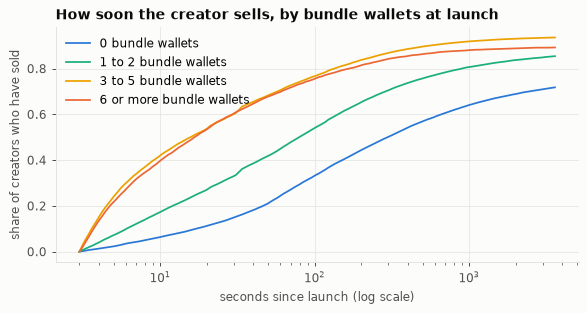

In [12]:
grid = np.logspace(np.log10(3), np.log10(3600), 150)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for label in BUNDLE_LABELS:
    part = holders[holders["bundle"] == label]
    ax.plot(grid, pf.event_share_by(part["dev_first_sell_dt_s"], grid), color=BUNDLE_COLOURS[label], label=f"{label} bundle wallets")
ax.set_xscale("log"); ax.set_xlabel("seconds since launch (log scale)"); ax.set_ylabel("share of creators who have sold")
ax.set_title("How soon the creator sells, by bundle wallets at launch"); ax.legend(loc="upper left")
plt.show()

### 2.1 Names: copies and their outcomes

A launch's *position* is the number of earlier launches with the same normalized name in the 34 days of
data. Position 0 is a name not seen before. The complete week starts 27 days into the data, so a "new"
name is new for at least 27 days.

In [13]:
position = pd.cut(study["nm_n_prior"], [-1, 0, 4, 19, 99, 1e9], labels=["new name", "1 to 4 earlier", "5 to 19", "20 to 99", "100 or more"])
frame = study[study["outcome"] != "unresolved"].assign(position=position)
by_position = frame.groupby("position", observed=True).agg(
    launches=("mint", "size"),
    creator_buyout=("outcome", lambda s: (s == "creator_buyout").mean()),
    graduated=("outcome", lambda s: (s == "graduated").mean()),
    rug_rule=("rugged", "mean"),
    own_copy=("nm_n_own", lambda s: (s > 0).mean()),
    median_peak_sol=("peak_rs", "median"))
display(by_position)

copies = task[task["nm_n_prior"] > 0].copy()
copies["kind"] = np.where(copies["nm_n_own"] > 0, "creator used the name before", "name used by others only")
copies["earlier"] = np.where(copies["nm_n_grad"] > 0, "an earlier one had graduated", "none had graduated")
selection = copies.groupby(["kind", "earlier"]).agg(launches=("mint", "size"), graduates=("y_grad", "mean"),
                                                    creator_sells_60s=("y_dev_exit", "mean"), median_bundle_wallets=("f10_bundle_wallets", "median"))
print("copies undecided at 3 s, by what was known about the name when they launched")
display(selection)
print(f"new names undecided at 3 s: {(task['nm_n_prior'] == 0).sum():,} launches, graduates {task.loc[task['nm_n_prior'] == 0, 'y_grad'].mean():.2%}")

,launches,creator_buyout,graduated,rug_rule,own_copy,median_peak_sol
position,,,,,,
new name,56743,0.0021,0.0148,0.6107,0.0000,1.4269
1 to 4 earlier,48016,0.0051,0.0175,0.6361,0.2438,1.6308
5 to 19,44717,0.0097,0.0183,0.6574,0.2581,2.2100
20 to 99,34447,0.0251,0.0192,0.6646,0.2451,2.9432
100 or more,14450,0.0732,0.0135,0.5880,0.2938,1.9859


copies undecided at 3 s, by what was known about the name when they launched


launches  graduates  creator_sells_60s  median_bundle_wallets
kind                         earlier                                                                                    
creator used the name before an earlier one had graduated      6291     0.0126             0.5139                 1.0000
                             none had graduated               24443     0.0032             0.2892                 0.0000
name used by others only     an earlier one had graduated     23309     0.0232             0.5153                 1.0000
                             none had graduated               63456     0.0172             0.4683                 1.0000

new names undecided at 3 s: 47,882 launches, graduates 0.95%


**The first look's "it pays to be first" does not hold up.** It reported that the first use of a popular
name graduates at 9.7% and the twenty-first at 1.7%. That compared positions *within names that went on
to be used twenty times*, which selects the names whose first launch did well. Counting position from
34 days of history and keeping every name, graduation is flat: 1.5% for a new name, 1.8 to 1.9% for
copies, 1.4% for the hundredth copy and later.

What does change with position is the share of creator buyouts, from 0.2% for new names to 7.3% for
names already used a hundred times: buyout launches are concentrated in a few heavily repeated names.

The second table conditions on what was knowable when a copy launched. A copy of a name of which an
earlier launch had already graduated graduates at 2.3%, against 1.7% otherwise and 0.95% for new
names. A creator reusing their own name, none of whose earlier launches graduated, almost never
graduates (0.3%). These are modest, real differences; whether they add to a model is tested in section 4.

### 2.2 How much does normalization miss? Near-duplicate names

Exact matching after normalization treats "dog coin" and "Dog-Coin" as one name but not "dogcoin2" or a
misspelling. To size what is missed, take names used only once in the week and look for their nearest
neighbour among all names by character 2- to 4-grams (TF-IDF, cosine similarity).

In [14]:
key_counts = study["name_key"].value_counts()
keys = key_counts.index[key_counts.index.str.len() >= 3].to_numpy()
vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), sublinear_tf=True, min_df=2, dtype=np.float32)
matrix = vectorizer.fit_transform(keys)
rng = np.random.default_rng(SEED)
singles = np.flatnonzero(key_counts.reindex(keys).to_numpy() == 1)
sample = rng.choice(singles, 4000, replace=False)
neighbours = NearestNeighbors(n_neighbors=2, metric="cosine", algorithm="brute").fit(matrix)
distance, index = neighbours.kneighbors(matrix[sample])
is_self = index[:, 0] == sample                 # the nearest hit is usually the name itself
nearest = np.where(is_self, index[:, 1], index[:, 0])
similarity = 1 - np.where(is_self, distance[:, 1], distance[:, 0])
links = pd.DataFrame({"name": keys[sample], "nearest": keys[nearest], "similarity": similarity,
                      "nearest_uses": key_counts.reindex(keys[nearest]).to_numpy()})
display(pd.DataFrame({"share of single-use names": [(links["similarity"] >= t).mean() for t in (0.6, 0.7, 0.8, 0.9)],
                      "... whose neighbour was used 5+ times": [((links["similarity"] >= t) & (links["nearest_uses"] >= 5)).mean() for t in (0.6, 0.7, 0.8, 0.9)]},
                     index=pd.Index([0.6, 0.7, 0.8, 0.9], name="similarity at least")))
close = links[(links["similarity"] >= 0.7) & (links["nearest_uses"] >= 5)]
contains = np.array([b in a for a, b in zip(close["name"], close["nearest"])])
print(f"of those {len(close)} close pairs, the single-use name contains its neighbour whole (a known name with text added): {contains.mean():.0%}")
print(f"single-use names are {(key_counts == 1).sum() / len(study):.1%} of launches")

,share of single-use names,... whose neighbour was used 5+ times
similarity at least,,
0.6000,0.6102,0.1452
0.7000,0.3625,0.0815
0.8000,0.1653,0.0360
0.9000,0.0420,0.0085


of those 326 close pairs, the single-use name contains its neighbour whole (a known name with text added): 73%
single-use names are 27.5% of launches


Normalization does most of the work: it merges 95,937 written names into 79,980. Beyond it, 17% of
single-use names have a neighbour at similarity 0.8 or more, and 36% at 0.7, but the neighbour is itself
rare in most cases: only 8% of single-use names are close (0.7) to a name used five times or more. In
three quarters of those pairs the rare name contains the common one whole: a known name with a word or
a number added, which Gao et al. call combo-squatting. Since single-use names are about a quarter of
launches, fuzzy matching would move roughly 2% of launches into an existing meme. I looked at about
thirty pairs by eye and did not label a sample, so there is no precision figure. Many names are
offensive, so none are printed here.

## 3. Preprocessing and split

### 3.1 The moment of prediction

Every early snapshot in the complete data is at most 3 seconds old (`f10_age` ≤ 3). So everything in
the snapshot is known **3 seconds after launch**, and that is the moment at which predictions are made.
A launch is in the task (`pf.eligible_at_snapshot`) if, at that moment, its fate is still open.

In [15]:
resolved_study = study[study["rugged"].notna()]
steps = pd.Series({
    "study population": len(study),
    "outcome resolved": len(resolved_study),
    "full snapshot exists": int(resolved_study["f10_bundle_wallets"].notna().sum()),
    "not a creator buyout, curve not already full": int((resolved_study["f10_bundle_wallets"].notna() & (resolved_study["dev_buy_sol"] < 80) & (resolved_study["f10_rs"] < 80)).sum()),
    "not rugged or graduated within the first 3 s = the task": len(task),
    "of which the creator holds tokens at 3 s": int(task["dev_holds"].sum()),
}, name="launches")
display(steps.to_frame())
no_snapshot = resolved_study[resolved_study["f10_bundle_wallets"].isna()]
print(f"launches without a full snapshot: rug rule {no_snapshot['rugged'].mean():.1%}, graduated {no_snapshot['graduated'].mean():.2%}; "
      f"with one: {resolved_study[resolved_study['f10_bundle_wallets'].notna()]['rugged'].mean():.1%}, {resolved_study[resolved_study['f10_bundle_wallets'].notna()]['graduated'].mean():.2%}")
early = resolved_study[(resolved_study["rugged"] == 1) & (resolved_study["rug_dt_s"] <= 3)]
print(f"rugged within 3 s of launch: {len(early):,} launches ({len(early)/len(resolved_study):.1%}); these are described, not predicted")
print("snapshot age: share at exactly 3.0 s:", f"{(task['f10_age'] == 3).mean():.1%}", "| quartiles of the rest:", task.loc[task["f10_age"] < 3, "f10_age"].quantile([0.25, 0.5, 0.75]).round(2).tolist())

,launches
study population,199986
outcome resolved,198373
full snapshot exists,186891
"not a creator buyout, curve not already full",183519
not rugged or graduated within the first 3 s = the task,165381
of which the creator holds tokens at 3 s,120362


launches without a full snapshot: rug rule 65.5%, graduated 3.01%; with one: 63.4%, 3.06%


rugged within 3 s of launch: 19,292 launches (9.7%); these are described, not predicted
snapshot age: share at exactly 3.0 s: 46.7% | quartiles of the rest: [0.15, 0.37, 0.92]


About 17% of the study population is already decided at 3 seconds: 9.7% are rugged by then, and the
rest are buyouts and instant graduations. They are a group of their own, described in section 1 and not
predicted.

**The sampling problem is small here.** Over the whole dataset the author warns that launches with a
snapshot are a non-random part (73% against 41% rugged). In the complete week, 94% of resolved launches
have a full snapshot and the two groups look alike (63% against 66% rugged, 3.1% against 3.0%
graduated).

**The age of the snapshot is itself informative.** 47% of snapshots are exactly 3.0 seconds old and the
rest mostly under one second. It is used as a feature; it is known at 3 seconds either way.

### 3.2 Targets

Section 1.3 showed that the dataset's rug label is close to a function of how large the curve became.
Three targets are therefore kept apart (`pf.add_targets`):

| Target | Meaning | Role |
| --- | --- | --- |
| `y_dev_exit` | the creator, holding tokens at 3 s, makes a first sale within the next 60 s | **primary.** A behaviour, timed, not defined through the curve's size |
| `y_grad` | the launch graduates (after 3 s, creator buyouts excluded) | **secondary.** The rare success; label checked by the author against the chain (recall 98.6%) |
| `y_rug` | the dataset's rug rule fires | reported to show what it measures; not a modelling target |

In [16]:
def auc(y, score):
    return roc_auc_score(y, score)

print("How well a single number known at 3 s 'predicts' each target (AUC, all task launches or holders):")
single = pd.DataFrame({
    "rug rule": [auc(task["y_rug"], task[c]) for c in ("f10_rs", "f10_bundle_wallets", "dev_buy_sol")],
    "creator sells within 60 s": [auc(holders["y_dev_exit"], holders[c]) for c in ("f10_rs", "f10_bundle_wallets", "dev_buy_sol")],
    "graduates": [auc(task["y_grad"], task[c]) for c in ("f10_rs", "f10_bundle_wallets", "dev_buy_sol")],
}, index=["SOL in the curve at 3 s", "bundle wallets", "creator's purchase, SOL"])
display(single)
above = task[task["f10_rs"] >= 5]
print(f"curve already holds 5 SOL at 3 s: {len(above):,} launches; the rug rule later fires on {above['y_rug'].mean():.1%}, graduation on {above['y_grad'].mean():.1%}")

How well a single number known at 3 s 'predicts' each target (AUC, all task launches or holders):


,rug rule,creator sells within 60 s,graduates
SOL in the curve at 3 s,0.8743,0.7657,0.8678
bundle wallets,0.7694,0.7070,0.8234
"creator's purchase, SOL",0.8838,0.7659,0.6927


curve already holds 5 SOL at 3 s: 38,460 launches; the rug rule later fires on 96.4%, graduation on 4.6%


The rug rule can be "predicted" with an AUC of 0.87 to 0.88 from one number, the SOL in the curve or the
creator's purchase, and it fires on 96% of the launches that already hold 5 SOL at 3 seconds. A model
for it would mostly relearn the rule.

### 3.3 Features, all known at 3 seconds

| Group | Features | Source |
| --- | --- | --- |
| basics | creator's purchase (SOL and share of supply), SOL in the curve, the creator's record: share of earlier launches already rugged, graduated | launch transaction, snapshot, own history |
| bundling | bundle wallets, insiders' share, the bundle's share (insiders minus creator), buys so far, age of the snapshot | snapshot |
| creator pace | earlier launches, launches in the last hour, seconds since the last one, share of earlier launches sold within a minute, hour of day, holder-reward flag | own history (34 days) |
| name | earlier uses of the name, uses in the last hour, earlier uses by the same creator, age of the name, earlier uses that had graduated (count and share), length | own history (34 days) |

The histories are computed by `pf.add_creator_history` and `pf.add_name_history` from all 34 days, and
count an earlier launch's rug, graduation or sale only if it had **already happened** when the present
launch started. The dataset's own reputation columns (`f10_rep_*`) are not used, because their exact
timing is not documented; they are compared below.

In [17]:
def design(frame):
    X = pd.DataFrame(index=frame.index)
    X["dev_buy_log"] = np.log1p(frame["dev_buy_sol"]);            X["dev_share"] = frame["dev_share"]
    X["curve_sol_log"] = np.log1p(frame["f10_rs"]);               X["cr_rug_rate"] = frame["cr_rug_rate"]
    X["cr_grad_rate"] = frame["cr_grad_rate"]
    X["bundle_wallets"] = frame["f10_bundle_wallets"];            X["insider_share"] = frame["f10_insider_share"]
    X["bundle_share"] = (frame["f10_insider_share"] - frame["f10_dev_share"]).clip(lower=0)
    X["n_buys"] = frame["f10_n_buys"];                            X["snapshot_age"] = frame["f10_age"]
    X["cr_n_prior_log"] = np.log1p(frame["cr_n_prior"]);          X["cr_n_1h_log"] = np.log1p(frame["cr_n_1h"])
    X["cr_gap_log"] = np.log1p(frame["cr_gap_s"]);                X["cr_fast_rate"] = frame["cr_fast_rate"]
    X["hour"] = frame["time"].dt.hour;                            X["holder_reward"] = frame["holder_reward"].astype(float)
    X["nm_n_prior_log"] = np.log1p(frame["nm_n_prior"]);          X["nm_n_1h_log"] = np.log1p(frame["nm_n_1h"])
    X["nm_n_own_log"] = np.log1p(frame["nm_n_own"]);              X["nm_age_log"] = np.log1p(frame["nm_age_s"])
    X["nm_n_grad_log"] = np.log1p(frame["nm_n_grad"]);            X["nm_grad_rate"] = frame["nm_grad_rate"]
    X["name_len"] = frame["name"].fillna("").str.len()
    return X

BASICS = ["dev_buy_log", "dev_share", "curve_sol_log", "cr_rug_rate", "cr_grad_rate"]
BUNDLING = ["bundle_wallets", "insider_share", "bundle_share", "n_buys", "snapshot_age"]
PACE = ["cr_n_prior_log", "cr_n_1h_log", "cr_gap_log", "cr_fast_rate", "hour", "holder_reward"]
NAME = ["nm_n_prior_log", "nm_n_1h_log", "nm_n_own_log", "nm_age_log", "nm_n_grad_log", "nm_grad_rate", "name_len"]
X_all = design(task)
display(X_all.describe(percentiles=[0.5, 0.99]).T.assign(missing=X_all.isna().mean()).round(3))
print("my creator history against the dataset's columns: correlation of log launch counts",
      f"{np.corrcoef(np.log1p(task['cr_n_prior']), np.log1p(task['f10_rep_n']))[0, 1]:.3f};",
      "mean rug share mine", f"{task['cr_rug_rate'].mean():.3f}", "theirs", f"{task['f10_rep_rug'].mean():.3f}")

,count,mean,std,min,50%,99%,max,missing
dev_buy_log,"165,381.0000",0.5260,0.6220,0.0000,0.2600,2.3980,4.3490,0.0000
dev_share,"165,381.0000",0.0360,0.0580,0.0000,0.0100,0.2680,0.7700,0.0000
curve_sol_log,"165,381.0000",0.9220,0.9510,0.0000,0.6370,3.2790,4.3930,0.0000
cr_rug_rate,"110,074.0000",0.5000,0.3790,0.0000,0.5960,1.0000,1.0000,0.3340
cr_grad_rate,"110,074.0000",0.0100,0.0640,0.0000,0.0000,0.2000,1.0000,0.3340
bundle_wallets,"165,381.0000",1.8590,2.8430,0.0000,1.0000,13.0000,31.0000,0.0000
insider_share,"165,381.0000",0.0850,0.1180,0.0000,0.0290,0.4930,0.7800,0.0000
bundle_share,"165,381.0000",0.0490,0.0900,0.0000,0.0010,0.4340,0.7790,0.0000
n_buys,"165,381.0000",1.7950,2.2780,0.0000,1.0000,10.0000,31.0000,0.0000
snapshot_age,"165,381.0000",1.7400,1.2760,0.0000,2.0100,3.0000,3.0000,0.0000


my creator history against the dataset's columns: correlation of log launch counts 0.998; mean rug share mine 0.500 theirs 0.648


A third of the launches are by creators with no earlier launch, so their record is missing; the name
history is missing for the 29% with a new name. The boosted models take missing values as they are; the
logistic models get the median and a "missing" indicator.

My launch counts agree with the dataset's own (correlation 0.998). The rug shares do not (0.50 against
0.65): mine count a rug only once it has happened, and I cannot tell from the documentation when theirs
are taken, so theirs stay out.

### 3.4 Split by time

Train on 27 to 30 September, choose on 1 October (dev), report once on 2 and 3 October (test). The split
is by launch time; no launch is in two parts.

In [18]:
parts = pf.time_split(task, DEV_START, TEST_START)
train_creators = set(parts["train"]["creator"])
summary = pd.DataFrame({name: {
    "launches": len(part), "creators": part["creator"].nunique(),
    "creator holds at 3 s": part["dev_holds"].mean(),
    "creator sells within 60 s (holders)": part.loc[part["dev_holds"], "y_dev_exit"].mean(),
    "graduates": part["y_grad"].mean(), "graduations": part["y_grad"].sum(),
    "rug rule": part["y_rug"].mean(),
    "launches by creators seen in train": part["creator"].isin(train_creators).mean(),
    "launches by first-time creators": (part["cr_n_prior"] == 0).mean(),
} for name, part in parts.items()}).T
display(summary)
display(task.groupby("day").agg(launches=("mint", "size"), holds=("dev_holds", "mean"), graduates=("y_grad", "mean"), rug_rule=("y_rug", "mean"),
                                median_bundle_wallets=("f10_bundle_wallets", "median"), median_curve_sol=("f10_rs", "median")))

,launches,creators,creator holds at 3 s,creator sells within 60 s (holders),graduates,graduations,rug rule,launches by creators seen in train,launches by first-time creators
train,"85,433.0000","37,105.0000",0.7664,0.4261,0.0133,"1,137.0000",0.6299,1.0000,0.3551
dev,"24,726.0000","10,917.0000",0.7412,0.4629,0.0142,352.0000,0.6442,0.4416,0.3082
test,"55,222.0000","22,331.0000",0.6620,0.4436,0.0136,753.0000,0.5546,0.3512,0.3142


,launches,holds,graduates,rug_rule,median_bundle_wallets,median_curve_sol
day,,,,,,
2026-09-27,20712,0.7874,0.0132,0.6509,1.0000,1.1002
2026-09-28,24330,0.7614,0.0137,0.6189,1.0000,1.0614
2026-09-29,22584,0.7565,0.0131,0.6164,1.0000,0.9022
2026-09-30,17807,0.7615,0.0132,0.6377,1.0000,0.9432
2026-10-01,24726,0.7412,0.0142,0.6442,1.0000,0.9898
2026-10-02,25302,0.7188,0.0150,0.6123,1.0000,0.8886
2026-10-03,29920,0.6139,0.0125,0.5058,0.0000,0.3462


The base rates are steady except on 3 October, where fewer creators hold tokens (61%), the median
curve is a third as large and the rug rule fires less. Test results are therefore also given per day.
44% of dev launches and 35% of test launches are by creators who also appear in train.

**Creators on both sides.** The idea file asked that no creator be on both sides of the split. That is
not how a warning would be used: a creator who returns is exactly the case in which their record
helps, and the record is built from the past only. So the split stays purely by time, and three things
guard against reading creator memory as skill: results are also reported for **first-time creators**
(no earlier launch in 34 days), intervals resample whole creators, and no creator identity is a feature.

### 3.5 Leakage checks

In [19]:
def fit_hgb(X, y):
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0, random_state=SEED).fit(X, y)

# 1. The trap the first look fell into: all launches with a snapshot, creator buyouts included.
loose = study[study["f10_bundle_wallets"].notna() & study["rugged"].notna()]
print(f"1. graduation from the SOL in the curve alone, all launches with a snapshot: AUC {auc(loose['graduated'] == 1, loose['f10_rs']):.3f}"
      f" | in the task (undecided at 3 s): AUC {auc(task['y_grad'], task['f10_rs']):.3f}")

# 2. Do the features still carry an event that happened before the prediction moment?
gap = (holders["dev_first_sell_dt_s"] - pf.PREDICTION_AGE)
print(f"2. creator's first sale earlier than 3 s among holders: {(gap <= 0).sum()} (must be 0); within 1 s after: {(gap <= 1).mean():.1%}")
reduced = (holders["f10_dev_share"] < 0.99 * holders["dev_share"]).mean()
print(f"   holders whose share at the snapshot is below their purchase (a transfer or partial sale already): {reduced:.1%}")

# 3. Histories: the same launches with the order of time reversed must give different numbers; and a shuffled-label model must sit at 0.5.
shuffled = holders.loc[parts["train"].index.intersection(holders.index)]
dev_h = holders.loc[parts["dev"].index.intersection(holders.index)]
X_shuffled, X_dev_h, null_aucs = design(shuffled), design(dev_h), []
for seed in range(5):
    y_perm = np.random.default_rng(seed).permutation(shuffled["y_dev_exit"].to_numpy())
    null_aucs.append(auc(dev_h["y_dev_exit"], fit_hgb(X_shuffled, y_perm).predict_proba(X_dev_h)[:, 1]))
print("3. models trained on shuffled labels, scored on dev: AUC", ", ".join(f"{a:.3f}" for a in null_aucs), "(0.5 expected on average)")

# 4. A feature that should know nothing: can the features tell dev from train? (drift, not leakage)
both = pd.concat([parts["train"].sample(20000, random_state=SEED), parts["dev"].sample(20000, random_state=SEED)])
is_dev = (both["time"] >= pd.Timestamp(DEV_START, tz="UTC")).astype(int).to_numpy()
half = np.random.default_rng(SEED).permutation(len(both))
fit_idx, score_idx = half[:20000], half[20000:]
drift = fit_hgb(design(both).drop(columns=["hour"]).iloc[fit_idx], is_dev[fit_idx])
print(f"4. telling dev launches from train launches by their features (hour removed): AUC {auc(is_dev[score_idx], drift.predict_proba(design(both).drop(columns=['hour']).iloc[score_idx])[:, 1]):.3f}")

1. graduation from the SOL in the curve alone, all launches with a snapshot: AUC 0.946 | in the task (undecided at 3 s): AUC 0.868
2. creator's first sale earlier than 3 s among holders: 0 (must be 0); within 1 s after: 5.6%
   holders whose share at the snapshot is below their purchase (a transfer or partial sale already): 0.0%


3. models trained on shuffled labels, scored on dev: AUC 0.463, 0.445, 0.542, 0.469, 0.575 (0.5 expected on average)


4. telling dev launches from train launches by their features (hour removed): AUC 0.869


1. **The buyout leak is real and is removed.** On all launches with a snapshot, the SOL in the curve
   alone gives an AUC of 0.946 for graduation, because buyouts are already complete. In the task it
   gives 0.868, which is honest signal: a fuller curve is closer to the threshold.
2. **No sale before the moment** is left among the holders. 5.6% sell within the following second: the
   target sits close to the features in time, by the nature of the problem.
3. **Shuffled labels** give AUCs scattered around 0.5, more widely than 18,000 independent launches
   would allow. That scatter is the clustering by creator, and the reason for creator-level intervals.
4. **The days differ.** A model can tell a dev launch from a train launch with an AUC of 0.87. Part is
   built in: the histories get longer as the data goes on. Part is a changing mix of prolific creators.
   This is drift and not leakage, and it limits how far results carry from one day to the next.

## 4. Baseline

**Tasks.**

- *Primary:* for a launch whose creator holds tokens at 3 seconds, the probability that the creator
  sells within the next 60 seconds.
- *Secondary:* for a launch undecided at 3 seconds, the probability that it graduates.

**Metrics, and why.**

| Metric | Why |
| --- | --- |
| AUC | ranking quality, independent of the base rate, comparable across days |
| average precision | the same for the rare event; the base rate is its floor |
| log loss | whether the probabilities can be believed, not only the order |
| rate in the top 10% (primary) or top 1% (secondary) of scores | the practical reading: what a user gets from acting on the highest scores |

**Protocol.** Fit on train. Compare candidates on dev only. One model per task is chosen there, by
average precision. The fixed baseline and the chosen model are then scored once on test, with 95%
intervals that resample creators.

**Fixed baseline.** Logistic regression on the *basics*: the creator's purchase, the SOL in the curve
and the creator's record. These are what a careful buyer already looks at, and the idea file named each
of them as a baseline. Hyperparameters of the boosted models are set once and not tuned.

In [20]:
def fit_logistic(X, y):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)).fit(X, y)

def scores(y, p, top):
    return {"AUC": roc_auc_score(y, p), "avg precision": average_precision_score(y, p), "log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
            f"rate in top {top:.0%}": pf.top_rate(y, p, top)}

CANDIDATES = {
    "fixed baseline: logistic, basics": (fit_logistic, BASICS),
    "logistic, basics + bundling": (fit_logistic, BASICS + BUNDLING),
    "logistic, all features": (fit_logistic, BASICS + BUNDLING + PACE + NAME),
    "boosting, basics": (fit_hgb, BASICS),
    "boosting, basics + bundling": (fit_hgb, BASICS + BUNDLING),
    "boosting, basics + pace": (fit_hgb, BASICS + PACE),
    "boosting, basics + name": (fit_hgb, BASICS + NAME),
    "boosting, all but bundling": (fit_hgb, BASICS + PACE + NAME),
    "boosting, all but name": (fit_hgb, BASICS + BUNDLING + PACE),
    "boosting, all features": (fit_hgb, BASICS + BUNDLING + PACE + NAME),
}

def run_task(target, rows, top):
    data = {name: part[rows(part)] for name, part in parts.items()}
    X = {name: design(part) for name, part in data.items()}
    y = {name: part[target].to_numpy() for name, part in data.items()}
    fitted, table = {}, {}
    table["base rate only"] = scores(y["dev"], np.full(len(y["dev"]), y["train"].mean()), top)
    for name, (fit, columns) in CANDIDATES.items():
        fitted[name] = fit(X["train"][columns], y["train"])
        table[name] = scores(y["dev"], fitted[name].predict_proba(X["dev"][columns])[:, 1], top)
    return data, X, y, fitted, pd.DataFrame(table).T

exit_data, exit_X, exit_y, exit_models, exit_dev = run_task("y_dev_exit", lambda part: part["dev_holds"], 0.10)
print(f"PRIMARY, dev day: creator sells within 60 s. Holders: train {len(exit_y['train']):,}, dev {len(exit_y['dev']):,}; base rate on dev {exit_y['dev'].mean():.1%}")
display(exit_dev)

# The same candidates on the dev launches of first-time creators, for whom there is no record to lean on.
first_time = (exit_data["dev"]["cr_n_prior"] == 0).to_numpy()
print(f"dev day, first-time creators only: {first_time.sum():,} holders, base rate {exit_y['dev'][first_time].mean():.1%}")
display(pd.DataFrame({name: scores(exit_y["dev"][first_time], exit_models[name].predict_proba(exit_X["dev"][columns])[:, 1][first_time], 0.10)
                      for name, (_, columns) in CANDIDATES.items() if name.startswith("boosting")}).T)

PRIMARY, dev day: creator sells within 60 s. Holders: train 65,480, dev 18,326; base rate on dev 46.3%


,AUC,avg precision,log loss,rate in top 10%
base rate only,0.5000,0.4629,0.6932,0.4484
"fixed baseline: logistic, basics",0.8247,0.7781,0.5141,0.9002
"logistic, basics + bundling",0.8260,0.7809,0.5126,0.8980
"logistic, all features",0.8879,0.8767,0.4208,0.9738
"boosting, basics",0.8742,0.8665,0.4396,0.9924
"boosting, basics + bundling",0.8776,0.8709,0.4345,0.9924
"boosting, basics + pace",0.9038,0.8985,0.3891,0.9945
"boosting, basics + name",0.8773,0.8713,0.4355,0.9913
"boosting, all but bundling",0.9052,0.8998,0.3866,0.9940
"boosting, all but name",0.9054,0.9010,0.3854,0.9951


dev day, first-time creators only: 6,195 holders, base rate 50.3%


,AUC,avg precision,log loss,rate in top 10%
"boosting, basics",0.7900,0.7717,0.5564,0.8677
"boosting, basics + bundling",0.8026,0.7832,0.5407,0.8855
"boosting, basics + pace",0.7865,0.7664,0.5616,0.8613
"boosting, basics + name",0.7974,0.7833,0.5488,0.8984
"boosting, all but bundling",0.7943,0.7746,0.5530,0.8661
"boosting, all but name",0.7964,0.7820,0.5483,0.8903
"boosting, all features",0.7968,0.7806,0.5487,0.8839


In [21]:
grad_data, grad_X, grad_y, grad_models, grad_dev = run_task("y_grad", lambda part: pd.Series(True, index=part.index), 0.01)
print(f"SECONDARY, dev day: graduates. Launches: train {len(grad_y['train']):,} ({grad_y['train'].sum()} graduations), dev {len(grad_y['dev']):,} ({grad_y['dev'].sum()}); base rate on dev {grad_y['dev'].mean():.2%}")
display(grad_dev)

SECONDARY, dev day: graduates. Launches: train 85,433 (1137 graduations), dev 24,726 (352); base rate on dev 1.42%


,AUC,avg precision,log loss,rate in top 1%
base rate only,0.5000,0.0142,0.0747,0.0202
"fixed baseline: logistic, basics",0.8613,0.2010,0.0580,0.3158
"logistic, basics + bundling",0.8628,0.1990,0.0581,0.3158
"logistic, all features",0.8652,0.1991,0.0579,0.3077
"boosting, basics",0.8647,0.1779,0.0589,0.2915
"boosting, basics + bundling",0.8616,0.1677,0.0593,0.2713
"boosting, basics + pace",0.8659,0.1766,0.0587,0.2955
"boosting, basics + name",0.8601,0.1709,0.0592,0.2753
"boosting, all but bundling",0.8627,0.1724,0.0587,0.2794
"boosting, all but name",0.8618,0.1704,0.0589,0.2672


**Primary task, dev day.**

- The fixed baseline reaches an AUC of 0.825. The same three basics in a boosted model reach 0.874, so
  much of the gain of "complex models" is non-linearity, not new information.
- **Bundling adds almost nothing:** +0.003 AUC to the basics, and nothing once the creator's pace is in.
  **Names add the same +0.003.**
- **The creator's pace adds +0.03,** and it is one feature: the share of the creator's earlier
  launches that were sold within a minute.
- **For first-time creators,** who have no record, every model is weaker (0.79 to 0.80), the pace
  features do nothing, and bundling is worth about +0.01.

**Secondary task, dev day.** No candidate beats the fixed baseline on average precision (0.20 against a
base rate of 0.014). The boosted models are slightly worse: with 1,137 graduations in train they overfit.

### 4.1 The test days

The model chosen on dev for each task, by average precision among the candidates, against the fixed
baseline. This cell was run after the choice was made.

In [22]:
BASELINE = "fixed baseline: logistic, basics"

def test_report(data, X, y, models, dev_table, top, label):
    chosen = dev_table.drop(index=["base rate only", BASELINE])["avg precision"].idxmax()
    part, truth = data["test"], y["test"]
    p_base = models[BASELINE].predict_proba(X["test"][CANDIDATES[BASELINE][1]])[:, 1]
    p_model = models[chosen].predict_proba(X["test"][CANDIDATES[chosen][1]])[:, 1]
    rows = {}
    for name, p in (("base rate only", np.full(len(truth), y["train"].mean())), (BASELINE, p_base), (f"chosen: {chosen}", p_model)):
        row = scores(truth, p, top)
        if name != "base rate only":
            for metric, fn in (("AUC", roc_auc_score), ("avg precision", average_precision_score)):
                _, lo, hi = pf.cluster_bootstrap(fn, part["creator"], truth, p, n_boot=200, seed=SEED)
                row[metric + " 95%"] = f"{lo:.3f} to {hi:.3f}"
        rows[name] = row
    print(f"{label}: test days, {len(truth):,} launches, {int(truth.sum()):,} events ({truth.mean():.2%})")
    display(pd.DataFrame(rows).T)
    for metric, fn in (("AUC", roc_auc_score), ("average precision", average_precision_score)):
        point, lo, hi = pf.cluster_bootstrap(lambda t, a, b: fn(t, a) - fn(t, b), part["creator"], truth, p_model, p_base, n_boot=200, seed=SEED)
        print(f"  chosen minus baseline, {metric}: {point:+.3f} (95% {lo:+.3f} to {hi:+.3f})")
    slices = {"2 October": part["day"] == "2026-10-02", "3 October": part["day"] == "2026-10-03",
              "first-time creators": part["cr_n_prior"] == 0, "returning creators": part["cr_n_prior"] > 0,
              "without the 100 most prolific creators": ~part["creator"].isin(task["creator"].value_counts().index[:100])}
    out = {}
    for name, mask in slices.items():
        m = mask.to_numpy()
        out[name] = {"launches": int(m.sum()), "events": int(truth[m].sum()), "base rate": truth[m].mean(),
                     "baseline AUC": roc_auc_score(truth[m], p_base[m]), "chosen AUC": roc_auc_score(truth[m], p_model[m]),
                     "baseline avg precision": average_precision_score(truth[m], p_base[m]), "chosen avg precision": average_precision_score(truth[m], p_model[m])}
    display(pd.DataFrame(out).T)
    return chosen, p_base, p_model

exit_chosen, exit_p_base, exit_p = test_report(exit_data, exit_X, exit_y, exit_models, exit_dev, 0.10, "PRIMARY, creator sells within 60 s")

PRIMARY, creator sells within 60 s: test days, 36,556 launches, 16,216 events (44.36%)


,AUC,avg precision,log loss,rate in top 10%,AUC 95%,avg precision 95%
base rate only,0.5000,0.4436,0.6874,0.4491,NaN,NaN
"fixed baseline: logistic, basics",0.8029,0.7424,0.5356,0.8832,0.785 to 0.817,0.713 to 0.766
"chosen: boosting, all but name",0.8861,0.8724,0.4168,0.9888,0.878 to 0.894,0.860 to 0.884


  chosen minus baseline, AUC: +0.083 (95% +0.072 to +0.098)


  chosen minus baseline, average precision: +0.130 (95% +0.113 to +0.151)


,launches,events,base rate,baseline AUC,chosen AUC,baseline avg precision,chosen avg precision
2 October,"18,188.0000","8,299.0000",0.4563,0.8106,0.8910,0.7726,0.8814
3 October,"18,368.0000","7,917.0000",0.4310,0.7952,0.8811,0.7135,0.8628
first-time creators,"12,743.0000","5,667.0000",0.4447,0.6815,0.7173,0.5963,0.6391
returning creators,"23,813.0000","10,549.0000",0.4430,0.8542,0.9390,0.8097,0.9334
without the 100 most prolific creators,"32,842.0000","14,684.0000",0.4471,0.7946,0.8706,0.7305,0.8542


In [23]:
grad_chosen, grad_p_base, grad_p = test_report(grad_data, grad_X, grad_y, grad_models, grad_dev, 0.01, "SECONDARY, graduates")

SECONDARY, graduates: test days, 55,222 launches, 753 events (1.36%)


,AUC,avg precision,log loss,rate in top 1%,AUC 95%,avg precision 95%
base rate only,0.5000,0.0136,0.0721,0.0109,NaN,NaN
"fixed baseline: logistic, basics",0.8761,0.2073,0.0544,0.3170,0.854 to 0.895,0.176 to 0.238
"chosen: logistic, all features",0.8845,0.2094,0.0539,0.3134,0.864 to 0.902,0.175 to 0.242


  chosen minus baseline, AUC: +0.008 (95% +0.006 to +0.011)


  chosen minus baseline, average precision: +0.002 (95% -0.004 to +0.008)


,launches,events,base rate,baseline AUC,chosen AUC,baseline avg precision,chosen avg precision
2 October,"25,302.0000",379.0000,0.0150,0.8610,0.8716,0.2047,0.2096
3 October,"29,920.0000",374.0000,0.0125,0.8886,0.8953,0.2138,0.2103
first-time creators,"17,350.0000",499.0000,0.0288,0.8084,0.8202,0.2537,0.2515
returning creators,"37,872.0000",254.0000,0.0067,0.8948,0.9034,0.1156,0.1254
without the 100 most prolific creators,"43,051.0000",714.0000,0.0166,0.8631,0.8720,0.2168,0.2185


**Primary.** The chosen model reaches an AUC of 0.886 against 0.803 for the fixed baseline, a difference
of +0.083 (95% +0.072 to +0.098), on both test days. Of the tenth of launches it scores highest, 99%
have a creator who sells within a minute, against a base rate of 44%. The gain is carried by returning
creators (0.939). **For first-time creators it is 0.717 against 0.682:** the model has mostly learned
that creators repeat themselves.

**Secondary.** The chosen model and the fixed baseline cannot be told apart on average precision (+0.002,
interval from -0.004 to +0.008). Both are useful in absolute terms: of the 1% of launches scored
highest, 31% graduate, against a base rate of 1.4%.

**Are the probabilities right?** Test launches in ten groups of predicted probability (primary task),
and the test launches ranked by the graduation score.

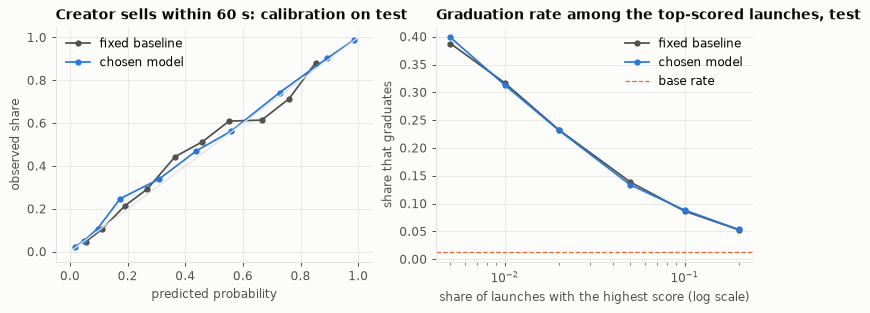

,launches,predicted,observed
group,,,
0,3656,0.0170,0.0224
1,3656,0.0487,0.0509
2,3655,0.0958,0.1078
3,3656,0.1746,0.2481
4,3655,0.3086,0.3384
5,3657,0.4379,0.4703
6,3654,0.5603,0.5638
7,3656,0.7270,0.7426
8,3655,0.8919,0.9029


share of all test graduations inside the top-scored launches: top 1%: 23%, top 5%: 49%, top 10%: 65%


In [24]:
def reliability(truth, p, groups=10):
    frame = pd.DataFrame({"truth": truth, "p": p})
    frame["group"] = pd.qcut(frame["p"], groups, labels=False, duplicates="drop")
    return frame.groupby("group").agg(launches=("truth", "size"), predicted=("p", "mean"), observed=("truth", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for (name, p, colour) in (("fixed baseline", exit_p_base, MUTED), ("chosen model", exit_p, BLUE)):
    table = reliability(exit_y["test"], p)
    axes[0].plot(table["predicted"], table["observed"], marker="o", ms=4, color=colour, label=name)
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1); axes[0].set_xlabel("predicted probability"); axes[0].set_ylabel("observed share")
axes[0].set_title("Creator sells within 60 s: calibration on test"); axes[0].legend(loc="upper left")

fractions = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
axes[1].plot(fractions, [pf.top_rate(grad_y["test"], grad_p_base, f) for f in fractions], marker="o", ms=4, color=MUTED, label="fixed baseline")
axes[1].plot(fractions, [pf.top_rate(grad_y["test"], grad_p, f) for f in fractions], marker="o", ms=4, color=BLUE, label="chosen model")
axes[1].axhline(grad_y["test"].mean(), color=ORANGE, lw=1, ls="--", label="base rate")
axes[1].set_xscale("log"); axes[1].set_xlabel("share of launches with the highest score (log scale)"); axes[1].set_ylabel("share that graduates")
axes[1].set_title("Graduation rate among the top-scored launches, test"); axes[1].legend(loc="upper right")
plt.show()
display(reliability(exit_y["test"], exit_p))
captured = [(f, pf.top_rate(grad_y["test"], grad_p, f) * f / grad_y["test"].mean()) for f in (0.01, 0.05, 0.10)]
print("share of all test graduations inside the top-scored launches:", ", ".join(f"top {f:.0%}: {c:.0%}" for f, c in captured))

The chosen model's probabilities are close to the observed shares over the whole range, slightly low in
the middle. For graduation, the top tenth of scores holds 65% of all graduations.

### 4.2 What the model uses

Permutation importance of the chosen primary model on the dev day: the drop in AUC when one feature is
shuffled.

In [25]:
def permutation_drop(model, X, y, columns, seed=SEED):
    base = roc_auc_score(y, model.predict_proba(X[columns])[:, 1])
    rng, drops = np.random.default_rng(seed), {}
    for column in columns:
        shuffled = X[columns].copy()
        shuffled[column] = rng.permutation(shuffled[column].to_numpy())
        drops[column] = base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1])
    return pd.Series(drops).sort_values(ascending=False)

importance = pd.DataFrame({
    "creator sells within 60 s": permutation_drop(exit_models[exit_chosen], exit_X["dev"], exit_y["dev"], CANDIDATES[exit_chosen][1]),
    "graduates": permutation_drop(grad_models[grad_chosen], grad_X["dev"], grad_y["dev"], CANDIDATES[grad_chosen][1]),
})
display(importance.sort_values("creator sells within 60 s", ascending=False).round(4))

,creator sells within 60 s,graduates
cr_fast_rate,0.1883,0.0015
dev_share,0.0229,0.0084
cr_rug_rate,0.0096,-0.0006
n_buys,0.0094,0.0001
dev_buy_log,0.0093,0.0092
cr_n_prior_log,0.0068,0.0007
curve_sol_log,0.0064,0.3417
cr_gap_log,0.0052,0.0015
bundle_share,0.0040,0.0007
insider_share,0.0031,0.0002


One feature carries the primary model: the creator's record of fast sales (0.19 of AUC). Everything
else is under 0.03, and each bundling feature under 0.01. Graduation is carried by the SOL already in
the curve (0.34); the largest name feature, earlier graduations under the same name, is worth 0.004.

## 5. Method fit

### 5.1 Survival analysis: when, not only whether

The idea proposed survival models for the time to the event. For the creator's first sale the setting
is unusually simple: every curve was followed until it was closed, so there is no censoring to speak of.
A Cox model is fitted on a sample of the training holders (time measured from the prediction moment,
creators who never sold censored at one hour) and compared with the classifier on two questions:
ranking of *who sells sooner* among those who sell, and "sold within h seconds" at several horizons.

In [26]:
COX_COLUMNS = ["dev_buy_log", "curve_sol_log", "bundle_wallets", "bundle_share", "n_buys", "cr_n_prior_log", "cr_fast_rate", "nm_n_own_log"]

def cox_frame(part):
    X = design(part)[COX_COLUMNS]
    X["cr_new"] = X["cr_fast_rate"].isna().astype(float)
    X = X.fillna(0.0)
    wait = part["dev_first_sell_dt_s"] - pf.PREDICTION_AGE
    return X, wait.fillna(3600.0).clip(upper=3600.0).to_numpy(), (wait <= 3600).fillna(False).to_numpy().astype(int)

train_h = exit_data["train"].sample(30000, random_state=SEED)
X_cox, wait_train, sold_train = cox_frame(train_h)
mean, std = X_cox.mean(), X_cox.std().replace(0, 1)
cox = PHReg(wait_train, (X_cox - mean) / std, status=sold_train, ties="breslow").fit()
display(pd.DataFrame({"hazard ratio per standard deviation": np.exp(cox.params), "95% low": np.exp(cox.conf_int()[:, 0]), "95% high": np.exp(cox.conf_int()[:, 1])}, index=X_cox.columns).round(3))

dev_hold = exit_data["dev"]
X_dev, wait_dev, sold_dev = cox_frame(dev_hold)
risk = ((X_dev - mean) / std).to_numpy() @ cox.params
p_class = exit_models[exit_chosen].predict_proba(exit_X["dev"][CANDIDATES[exit_chosen][1]])[:, 1]
sellers = sold_dev == 1
compare = {"ranking of sellers by time (concordance)": {"Cox model": pf.concordance(wait_dev[sellers], risk[sellers], seed=SEED),
                                                           "classifier for 60 s": pf.concordance(wait_dev[sellers], p_class[sellers], seed=SEED)}}
for h in (10, 60, 300, 1800):
    within = (wait_dev <= h) & sellers
    compare[f"sold within {h} s (AUC), base rate {within.mean():.0%}"] = {"Cox model": roc_auc_score(within, risk), "classifier for 60 s": roc_auc_score(within, p_class)}
display(pd.DataFrame(compare).T)

# Is the effect of bundling the same early and late? Fit separately on the first 30 s and on those still holding after it.
early = PHReg(np.minimum(wait_train, 30.0), (X_cox - mean) / std, status=sold_train * (wait_train <= 30)).fit()
late_rows = wait_train > 30
late = PHReg(wait_train[late_rows] - 30.0, ((X_cox - mean) / std)[late_rows], status=sold_train[late_rows]).fit()
display(pd.DataFrame({"hazard ratio, first 30 s": np.exp(early.params), "hazard ratio, after 30 s": np.exp(late.params)}, index=X_cox.columns).round(3))

,hazard ratio per standard deviation,95% low,95% high
dev_buy_log,1.1980,1.1550,1.2410
curve_sol_log,1.3050,1.2290,1.3860
bundle_wallets,1.0440,1.0090,1.0800
bundle_share,0.9270,0.8910,0.9630
n_buys,1.0410,1.0100,1.0740
cr_n_prior_log,1.1580,1.1370,1.1790
cr_fast_rate,2.1040,2.0690,2.1390
nm_n_own_log,0.8460,0.8340,0.8590
cr_new,1.3410,1.3130,1.3710


,Cox model,classifier for 60 s
ranking of sellers by time (concordance),0.7446,0.7734
"sold within 10 s (AUC), base rate 24%",0.8849,0.9070
"sold within 60 s (AUC), base rate 46%",0.8699,0.9054
"sold within 300 s (AUC), base rate 68%",0.8216,0.8552
"sold within 1800 s (AUC), base rate 80%",0.8058,0.8305


,"hazard ratio, first 30 s","hazard ratio, after 30 s"
dev_buy_log,1.0320,1.1500
curve_sol_log,1.6590,1.3210
bundle_wallets,1.0870,0.9650
bundle_share,0.8950,0.8170
n_buys,1.0430,1.0560
cr_n_prior_log,1.4770,0.9860
cr_fast_rate,3.7450,1.6310
nm_n_own_log,0.9080,0.8340
cr_new,3.0740,1.0610


**The Cox model does not fit, and is not needed.**

- The classifier trained for the 60-second question ranks sellers by time better than the Cox model
  (concordance 0.77 against 0.74) and is better at every horizon from 10 seconds to 30 minutes.
- The effects are not proportional over time, which the Cox model assumes. The creator's record of fast
  sales multiplies the hazard by 3.7 in the first 30 seconds and by 1.6 after; being a new creator by
  3.1 and then 1.1; bundle wallets by 1.09 and then 0.97.
- There is no censoring to handle: every curve was followed to its end.

What the survival view does contribute is the framing: a fixed moment of prediction, launches at risk at
that moment, and a horizon. A model per horizon, or a discrete-time hazard model with time-varying
effects, fits this data; a single proportional-hazards model does not. Competing-risk machinery is not
needed for the same reason.

### 5.2 Summary of this notebook

| Question | Answer |
| --- | --- |
| Does the data exist? | Yes: 1.18 million launches, of which 200,000 form a clean study population (classic, SOL, fully recorded week) and 165,000 are still undecided 3 seconds after launch. |
| Are the labels usable? | Graduation: yes, once creator buyouts (45% of graduations) are separated. The rug label: no, as a target; it is close to "the curve reached 5 SOL and did not graduate". The creator's first sale is used instead. |
| Does bundling predict outcomes? | In raw numbers strongly. With the size of the curve held fixed, hardly: +0.003 AUC over the basics. |
| Do copied names predict outcomes? | Hardly. The first look's "first is best" came from selecting names by their later popularity. |
| Preprocessing? | Fix the prediction moment at 3 s; drop what is decided by then; build creator and name histories from the past only; set aside mayhem and non-SOL launches. |
| Split? | By time: 4 days train, 1 dev, 2 test; first-time creators reported separately; intervals resample creators. |
| Baseline? | Logistic regression on the creator's purchase, the SOL in the curve and the creator's record: AUC 0.80 (creator sells within a minute), 0.88 (graduation) on test. |
| Do more complex models help? | For the creator's sale, yes: 0.89, almost all from the creator's record of fast sales. For graduation, no. |
| Do survival models fit? | Not the proportional-hazards kind. Horizon-specific classifiers do better. |

The full discussion is in [`research/memecoin_launch_writeup.md`](../../research/memecoin_launch_writeup.md).